<a href="https://colab.research.google.com/github/Ppcat99/Data-Science_project_Parth-Patel/blob/main/Sales_BA_DA_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Sales BA–DA Case Study

## 1. Initial Data Inspection

# Purpose:
# Inspect the source dataset, identify its structure and business context,
# and assess whether it supports the proposed analytical questions.

# This is an independent portfolio case study.
# The company context and stakeholder requirements are simulated.

In [2]:
import pandas as pd
from google.colab import files

uploaded = files.upload()


Saving Auto Sales data.csv to Auto Sales data.csv


In [3]:
if len(uploaded) != 1:
    raise ValueError("Upload exactly one dataset file for this step.")

filename = next(iter(uploaded))
print("Uploaded file:", filename)

if filename.lower().endswith(".csv"):
    df_raw = pd.read_csv(filename)

elif filename.lower().endswith(".xlsx"):
    workbook = pd.ExcelFile(filename)
    print("Workbook sheets:", workbook.sheet_names)
    df_raw = pd.read_excel(workbook, sheet_name=0)

else:
    raise ValueError("Please upload a CSV or XLSX file.")

df = df_raw.copy()
# We create a another copy so we leave the raw data alone

Uploaded file: Auto Sales data.csv


In [4]:
pd.set_option("display.max_columns", None)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

display(df.head(10))
# 20 columns and 2747 rows of numbers

Rows: 2747
Columns: 20

Column names:
['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER', 'SALES', 'ORDERDATE', 'DAYS_SINCE_LASTORDER', 'STATUS', 'PRODUCTLINE', 'MSRP', 'PRODUCTCODE', 'CUSTOMERNAME', 'PHONE', 'ADDRESSLINE1', 'CITY', 'POSTALCODE', 'COUNTRY', 'CONTACTLASTNAME', 'CONTACTFIRSTNAME', 'DEALSIZE']


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,DAYS_SINCE_LASTORDER,STATUS,PRODUCTLINE,MSRP,PRODUCTCODE,CUSTOMERNAME,PHONE,ADDRESSLINE1,CITY,POSTALCODE,COUNTRY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,24/02/2018,828,Shipped,Motorcycles,95,S10_1678,Land of Toys Inc.,2125557818,897 Long Airport Avenue,NYC,10022,USA,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,07/05/2018,757,Shipped,Motorcycles,95,S10_1678,Reims Collectables,26.47.1555,59 rue de l'Abbaye,Reims,51100,France,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,01/07/2018,703,Shipped,Motorcycles,95,S10_1678,Lyon Souveniers,+33 1 46 62 7555,27 rue du Colonel Pierre Avia,Paris,75508,France,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,25/08/2018,649,Shipped,Motorcycles,95,S10_1678,Toys4GrownUps.com,6265557265,78934 Hillside Dr.,Pasadena,90003,USA,Young,Julie,Medium
4,10168,36,96.66,1,3479.76,28/10/2018,586,Shipped,Motorcycles,95,S10_1678,Technics Stores Inc.,6505556809,9408 Furth Circle,Burlingame,94217,USA,Hirano,Juri,Medium
5,10180,29,86.13,9,2497.77,11/11/2018,573,Shipped,Motorcycles,95,S10_1678,Daedalus Designs Imports,20.16.1555,"184, chausse de Tournai",Lille,59000,France,Rance,Martine,Small
6,10188,48,114.84,1,5512.32,18/11/2018,567,Shipped,Motorcycles,95,S10_1678,Herkku Gifts,+47 2267 3215,"Drammen 121, PR 744 Sentrum",Bergen,N 5804,Norway,Oeztan,Veysel,Medium
7,10211,41,114.84,14,4708.44,15/01/2019,510,Shipped,Motorcycles,95,S10_1678,Auto Canal Petit,(1) 47.55.6555,"25, rue Lauriston",Paris,75016,France,Perrier,Dominique,Medium
8,10223,37,107.18,1,3965.66,20/02/2019,475,Shipped,Motorcycles,95,S10_1678,"Australian Collectors, Co.",03 9520 4555,636 St Kilda Road,Melbourne,3004,Australia,Ferguson,Peter,Medium
9,10237,23,101.44,7,2333.12,05/04/2019,432,Shipped,Motorcycles,95,S10_1678,Vitachrome Inc.,2125551500,2678 Kingston Rd.,NYC,10022,USA,Frick,Michael,Small


In [5]:
df.info()

inspection_summary = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True)
})

display(inspection_summary)

print("Exact duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2747 entries, 0 to 2746
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ORDERNUMBER           2747 non-null   int64  
 1   QUANTITYORDERED       2747 non-null   int64  
 2   PRICEEACH             2747 non-null   float64
 3   ORDERLINENUMBER       2747 non-null   int64  
 4   SALES                 2747 non-null   float64
 5   ORDERDATE             2747 non-null   object 
 6   DAYS_SINCE_LASTORDER  2747 non-null   int64  
 7   STATUS                2747 non-null   object 
 8   PRODUCTLINE           2747 non-null   object 
 9   MSRP                  2747 non-null   int64  
 10  PRODUCTCODE           2747 non-null   object 
 11  CUSTOMERNAME          2747 non-null   object 
 12  PHONE                 2747 non-null   object 
 13  ADDRESSLINE1          2747 non-null   object 
 14  CITY                  2747 non-null   object 
 15  POSTALCODE           

,data_type,missing_count,missing_percent,unique_values
ORDERNUMBER,int64,0,0.0,298
QUANTITYORDERED,int64,0,0.0,58
PRICEEACH,float64,0,0.0,1843
ORDERLINENUMBER,int64,0,0.0,18
SALES,float64,0,0.0,2690
ORDERDATE,object,0,0.0,246
DAYS_SINCE_LASTORDER,int64,0,0.0,1832
STATUS,object,0,0.0,6
PRODUCTLINE,object,0,0.0,7
MSRP,int64,0,0.0,80


Exact duplicate rows: 0


In [6]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

display(df.head(5))

display(
    df.isna()
      .sum()
      .sort_values(ascending=False)
      .rename("missing_count")
      .to_frame()
)

Rows: 2747
Columns: 20

Column names:
['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER', 'SALES', 'ORDERDATE', 'DAYS_SINCE_LASTORDER', 'STATUS', 'PRODUCTLINE', 'MSRP', 'PRODUCTCODE', 'CUSTOMERNAME', 'PHONE', 'ADDRESSLINE1', 'CITY', 'POSTALCODE', 'COUNTRY', 'CONTACTLASTNAME', 'CONTACTFIRSTNAME', 'DEALSIZE']


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,DAYS_SINCE_LASTORDER,STATUS,PRODUCTLINE,MSRP,PRODUCTCODE,CUSTOMERNAME,PHONE,ADDRESSLINE1,CITY,POSTALCODE,COUNTRY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,24/02/2018,828,Shipped,Motorcycles,95,S10_1678,Land of Toys Inc.,2125557818,897 Long Airport Avenue,NYC,10022,USA,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,07/05/2018,757,Shipped,Motorcycles,95,S10_1678,Reims Collectables,26.47.1555,59 rue de l'Abbaye,Reims,51100,France,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,01/07/2018,703,Shipped,Motorcycles,95,S10_1678,Lyon Souveniers,+33 1 46 62 7555,27 rue du Colonel Pierre Avia,Paris,75508,France,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,25/08/2018,649,Shipped,Motorcycles,95,S10_1678,Toys4GrownUps.com,6265557265,78934 Hillside Dr.,Pasadena,90003,USA,Young,Julie,Medium
4,10168,36,96.66,1,3479.76,28/10/2018,586,Shipped,Motorcycles,95,S10_1678,Technics Stores Inc.,6505556809,9408 Furth Circle,Burlingame,94217,USA,Hirano,Juri,Medium


,missing_count
ORDERNUMBER,0
QUANTITYORDERED,0
PRICEEACH,0
ORDERLINENUMBER,0
SALES,0
ORDERDATE,0
DAYS_SINCE_LASTORDER,0
STATUS,0
PRODUCTLINE,0
MSRP,0


In [7]:
### Product Categories and Order Statuses ###

# Purpose:
# Identify the types of products represented in the dataset and review the
# recorded order statuses before defining analytical data.

In [8]:
for column in ["PRODUCTLINE", "STATUS"]:
    if column in df.columns:
        print(f"\n{column} — row counts:")
        display(
            df[column]
            .value_counts(dropna=False)
            .rename_axis(column)
            .reset_index(name="row_count")
        )
    else:
        print(f"{column} not found. Check the actual column name.")

print("\nAvailable columns:")
print(df.columns.tolist())


PRODUCTLINE — row counts:


,PRODUCTLINE,row_count
0,Classic Cars,949
1,Vintage Cars,579
2,Motorcycles,313
3,Planes,304
4,Trucks and Buses,295
5,Ships,230
6,Trains,77



STATUS — row counts:


,STATUS,row_count
0,Shipped,2541
1,Cancelled,60
2,Resolved,47
3,On Hold,44
4,In Process,41
5,Disputed,14



Available columns:
['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER', 'SALES', 'ORDERDATE', 'DAYS_SINCE_LASTORDER', 'STATUS', 'PRODUCTLINE', 'MSRP', 'PRODUCTCODE', 'CUSTOMERNAME', 'PHONE', 'ADDRESSLINE1', 'CITY', 'POSTALCODE', 'COUNTRY', 'CONTACTLASTNAME', 'CONTACTFIRSTNAME', 'DEALSIZE']


In [9]:
if "ORDERDATE" in df.columns:
    print("Current date-column type:", df["ORDERDATE"].dtype)
    display(df[["ORDERDATE"]].head(10))
else:
    print("ORDERDATE not found. Check the actual column name.")

Current date-column type: object


,ORDERDATE
0,24/02/2018
1,07/05/2018
2,01/07/2018
3,25/08/2018
4,28/10/2018
5,11/11/2018
6,18/11/2018
7,15/01/2019
8,20/02/2019
9,05/04/2019


In [10]:
### Numeric Data Validation ###

# Purpose:
# Review Quantities, Prices, and recorded Sales values for missing,
# non-numeric, zero, negative, or usually large values.

# Flagged values will be investigated, not automatically removed.

In [11]:
expected_columns = ["QUANTITYORDERED", "PRICEEACH", "SALES", "MSRP"]
numeric_columns = [col for col in expected_columns if col in df.columns]

if not numeric_columns:
    print("Expected fields not found. Available columns:")
    print(df.columns.tolist())
else:
    numeric_check = df[numeric_columns].apply(
        pd.to_numeric, errors="coerce"
    )

    display(numeric_check.describe().T)

    checks = pd.DataFrame({
        "original_missing": df[numeric_columns].isna().sum(),
        "non_numeric_values": (
            df[numeric_columns].notna() & numeric_check.isna()
        ).sum(),
        "zero_values": numeric_check.eq(0).sum(),
        "negative_values": numeric_check.lt(0).sum()
    })

    display(checks)

,count,mean,std,min,25%,50%,75%,max
QUANTITYORDERED,2747.0,35.103021,9.762135,6.00,27.000,35.00,43.000,97.00
PRICEEACH,2747.0,101.098952,42.042549,26.88,68.745,95.55,127.100,252.87
SALES,2747.0,3553.047583,1838.953901,482.13,2204.350,3184.80,4503.095,14082.80
MSRP,2747.0,100.691664,40.114802,33.00,68.000,99.00,124.000,214.00


,original_missing,non_numeric_values,zero_values,negative_values
QUANTITYORDERED,0,0,0,0
PRICEEACH,0,0,0,0
SALES,0,0,0,0
MSRP,0,0,0,0


In [12]:
if "SALES" in numeric_columns:
    largest_sales_index = numeric_check["SALES"].nlargest(10).index
    display(df.loc[largest_sales_index])

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,DAYS_SINCE_LASTORDER,STATUS,PRODUCTLINE,MSRP,PRODUCTCODE,CUSTOMERNAME,PHONE,ADDRESSLINE1,CITY,POSTALCODE,COUNTRY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
571,10407,76,185.30,2,14082.8,22/04/2020,611,On Hold,Vintage Cars,170,S18_1749,The Sharp Gifts Warehouse,4085553659,3086 Ingle Ln.,San Jose,94217,USA,Frick,Sue,Large
714,10322,50,250.73,6,12536.5,04/11/2019,924,Shipped,Vintage Cars,127,S18_2325,Online Diecast Creations Co.,6035558647,2304 Long Airport Avenue,Nashua,62005,USA,Young,Valarie,Large
49,10424,50,240.02,6,12001.0,31/05/2020,50,In Process,Classic Cars,214,S10_1949,Euro Shopping Channel,(91) 555 94 44,"C/ Moralzarzal, 86",Madrid,28034,Spain,Freyre,Diego,Large
1020,10412,60,198.13,9,11887.8,03/05/2020,1049,Shipped,Classic Cars,169,S18_3232,Euro Shopping Channel,(91) 555 94 44,"C/ Moralzarzal, 86",Madrid,28034,Spain,Freyre,Diego,Large
96,10403,66,180.10,9,11886.6,08/04/2020,150,Shipped,Motorcycles,193,S10_4698,"UK Collectables, Ltd.",(171) 555-2282,Berkeley Gardens 12 Brewery,Liverpool,WX1 6LT,UK,Devon,Elizabeth,Large
1930,10405,76,154.47,3,11739.7,14/04/2020,1978,Shipped,Classic Cars,140,S24_3856,Mini Caravy,88.60.1555,"24, place Kluber",Strasbourg,67000,France,Citeaux,Frederique,Large
42,10312,48,242.16,3,11623.7,21/10/2019,266,Shipped,Classic Cars,214,S10_1949,Mini Gifts Distributors Ltd.,4155551450,5677 Strong St.,San Rafael,97562,USA,Nelson,Valarie,Large
176,10127,46,245.20,2,11279.2,03/06/2018,905,Shipped,Classic Cars,207,S12_1108,Muscle Machine Inc,2125557413,4092 Furth Circle,NYC,10022,USA,Young,Jeff,Large
28,10150,45,244.30,8,10993.5,19/09/2018,649,Shipped,Classic Cars,214,S10_1949,"Dragon Souveniers, Ltd.",+65 221 7555,"Bronz Sok., Bronz Apt. 3/6 Tesvikiye",Singapore,79903,Singapore,Natividad,Eric,Large
1779,10339,55,195.60,13,10758.0,23/11/2019,1970,Shipped,Vintage Cars,88,S24_3151,"Tokyo Collectables, Ltd",+81 3 3584 0555,2-2-8 Roppongi,Minato-ku,106-0032,Japan,Shimamura,Akiko,Large


In [13]:
# How many distinct orders have each status, and how much recorded sales value is
# associated with them?

### Order-Status Analysis ###

# Purpose:
# Measure the number of distict orders and recorded sales value associated with
# each order status.

# Recorded Sales value is not automatically completed revenue, lost revenue,
# or recoverable revenue.

In [14]:
status_summary = (
    df.groupby("STATUS", dropna=False)
      .agg(
          row_count=("ORDERNUMBER", "size"),
          distinct_orders=("ORDERNUMBER", "nunique"),
          recorded_sales_value=("SALES", "sum")
      )
      .reset_index()
      .sort_values("recorded_sales_value", ascending=False)
)

total_value = status_summary["recorded_sales_value"].sum()

status_summary["value_share_percent"] = (
    status_summary["recorded_sales_value"] / total_value * 100
).round(2) if total_value != 0 else float("nan")

display(status_summary)

statuses_per_order = (
    df.groupby("ORDERNUMBER")["STATUS"]
      .nunique(dropna=False)
)

print(
    "Orders appearing under more than one status:",
    (statuses_per_order > 1).sum()
)

# 92.41% of sales order shipped

,STATUS,row_count,distinct_orders,recorded_sales_value,value_share_percent
5,Shipped,2541,277,9019093.94,92.41
0,Cancelled,60,4,194487.48,1.99
3,On Hold,44,4,178979.19,1.83
4,Resolved,47,4,150718.28,1.54
2,In Process,41,6,144729.96,1.48
1,Disputed,14,3,72212.86,0.74


Orders appearing under more than one status: 0


In [15]:
total_orders = df["ORDERNUMBER"].nunique()

status_summary["order_share_percent"] = (
    status_summary["distinct_orders"] / total_orders * 100
).round(2)

display(
    status_summary[
        [
            "STATUS",
            "distinct_orders",
            "order_share_percent",
            "recorded_sales_value",
            "value_share_percent"
        ]
    ]
)

# 92.95% of people order shipped

,STATUS,distinct_orders,order_share_percent,recorded_sales_value,value_share_percent
5,Shipped,277,92.95,9019093.94,92.41
0,Cancelled,4,1.34,194487.48,1.99
3,On Hold,4,1.34,178979.19,1.83
4,Resolved,4,1.34,150718.28,1.54
2,In Process,6,2.01,144729.96,1.48
1,Disputed,3,1.01,72212.86,0.74


In [16]:
### Recorded Sales Value by Order Status ###

# Objective:
# Compare each status's share of distinct orders with its share of
# recorded sales value.

# This analysis does not establish collected revenue, lost revenue,
# or the current outcome of historical orders.

In [17]:
review_statuses = [
    "Cancelled", "On Hold", "Resolved", "In Process", "Disputed"
]

order_review = (
    df[df["STATUS"].isin(review_statuses)]
    .groupby(["ORDERNUMBER", "STATUS"], dropna=False)
    .agg(
        customer=("CUSTOMERNAME", "first"),
        order_date=("ORDERDATE", "first"),
        recorded_order_value=("SALES", "sum"),
        total_quantity=("QUANTITYORDERED", "sum"),
        product_lines=(
            "PRODUCTLINE",
            lambda x: ", ".join(sorted(x.dropna().astype(str).unique()))
        )
    )
    .reset_index()
    .sort_values("recorded_order_value", ascending=False)
)

display(order_review)

# May was highest count of orders (10) in the selected non-shipped status.
# According to the non selling list Vintage cars was most problems selling (15)

,ORDERNUMBER,STATUS,customer,order_date,recorded_order_value,total_quantity,product_lines
11,10407,On Hold,The Sharp Gifts Warehouse,22/04/2020,57883.09,571,"Classic Cars, Vintage Cars"
8,10386,Resolved,Euro Shopping Channel,01/03/2020,53815.72,650,"Planes, Ships, Vintage Cars"
3,10253,Cancelled,"UK Collectables, Ltd.",01/06/2019,50408.25,429,Classic Cars
4,10262,Cancelled,Euro Shopping Channel,24/06/2019,50010.65,605,"Planes, Ships, Vintage Cars"
1,10167,Cancelled,Scandinavian Gift Ideas,23/10/2018,48710.92,550,"Classic Cars, Planes, Ships, Vintage Cars"
12,10414,On Hold,Gifts4AllAges.com,06/05/2020,48316.89,506,"Classic Cars, Ships, Trains, Vintage Cars"
9,10401,On Hold,Tekni Collectables Inc.,03/04/2020,46519.00,585,"Motorcycles, Planes, Vintage Cars"
2,10248,Cancelled,Land of Toys Inc.,07/05/2019,45357.66,454,"Classic Cars, Ships, Trains, Vintage Cars"
7,10367,Resolved,Toys4GrownUps.com,12/01/2020,44273.36,469,"Classic Cars, Vintage Cars"
15,10420,In Process,Souveniers And Things Co.,29/05/2020,43971.43,532,"Classic Cars, Vintage Cars"


In [18]:
### Customer-level Order Review ###

# Objective:
# Identify customers with the largest number of distinct orders recorded as
# Cancelled, On hold, Reserved, In process, Shipped or Disputed.

# These statuses identify records for review; they do not establish customer
# fault or confirmed business failure

In [19]:
review_statuses = [
    "Cancelled", "Resolved", "Shipped", "On Hold", "In Process", "Disputed"
]

customer_orders = df[
    ["CUSTOMERNAME", "ORDERNUMBER", "STATUS"]
].drop_duplicates()

if customer_orders["ORDERNUMBER"].duplicated().any():
    raise ValueError(
        "Some order numbers have multiple customer/status combinations. "
        "Inspect these before counting."
    )

review_orders = customer_orders[
    customer_orders["STATUS"].isin(review_statuses)
]

customer_review = pd.crosstab(
    review_orders["CUSTOMERNAME"],
    review_orders["STATUS"]
).reindex(columns=review_statuses, fill_value=0)

customer_review["review_orders"] = (
    customer_review[review_statuses].sum(axis=1)
)

total_customer_orders = (
    customer_orders.groupby("CUSTOMERNAME")["ORDERNUMBER"].nunique()
)

customer_review["total_orders"] = total_customer_orders.reindex(
    customer_review.index
)

customer_review["review_share_pct"] = (
    customer_review["review_orders"]
    / customer_review["total_orders"] * 100
).round(2)

customer_review = customer_review.sort_values(
    ["review_orders", "review_share_pct"],
    ascending=[False, False]
)

display(customer_review.head(15))

# Most of business comes from Euro Shipping channel and Mini Gifts Dist Ltd.

STATUS,Cancelled,Resolved,Shipped,On Hold,In Process,Disputed,review_orders,total_orders,review_share_pct
CUSTOMERNAME,,,,,,,,,
Euro Shopping Channel,1,1,22,0,1,1,26,26,100.0
Mini Gifts Distributors Ltd.,0,0,16,0,1,0,17,17,100.0
"Australian Collectors, Co.",0,0,5,0,0,0,5,5,100.0
Danish Wholesale Imports,0,1,3,0,0,1,5,5,100.0
"Dragon Souveniers, Ltd.",0,0,5,0,0,0,5,5,100.0
Reims Collectables,0,0,5,0,0,0,5,5,100.0
"Anna's Decorations, Ltd",0,0,4,0,0,0,4,4,100.0
Baane Mini Imports,0,0,4,0,0,0,4,4,100.0
"Blauer See Auto, Co.",0,0,4,0,0,0,4,4,100.0


In [20]:
display(
    order_review.sort_values(
        "recorded_order_value",
        ascending=False
    )
)

# Order value was Sharp Gifts Warehouse

,ORDERNUMBER,STATUS,customer,order_date,recorded_order_value,total_quantity,product_lines
11,10407,On Hold,The Sharp Gifts Warehouse,22/04/2020,57883.09,571,"Classic Cars, Vintage Cars"
8,10386,Resolved,Euro Shopping Channel,01/03/2020,53815.72,650,"Planes, Ships, Vintage Cars"
3,10253,Cancelled,"UK Collectables, Ltd.",01/06/2019,50408.25,429,Classic Cars
4,10262,Cancelled,Euro Shopping Channel,24/06/2019,50010.65,605,"Planes, Ships, Vintage Cars"
1,10167,Cancelled,Scandinavian Gift Ideas,23/10/2018,48710.92,550,"Classic Cars, Planes, Ships, Vintage Cars"
12,10414,On Hold,Gifts4AllAges.com,06/05/2020,48316.89,506,"Classic Cars, Ships, Trains, Vintage Cars"
9,10401,On Hold,Tekni Collectables Inc.,03/04/2020,46519.00,585,"Motorcycles, Planes, Vintage Cars"
2,10248,Cancelled,Land of Toys Inc.,07/05/2019,45357.66,454,"Classic Cars, Ships, Trains, Vintage Cars"
7,10367,Resolved,Toys4GrownUps.com,12/01/2020,44273.36,469,"Classic Cars, Vintage Cars"
15,10420,In Process,Souveniers And Things Co.,29/05/2020,43971.43,532,"Classic Cars, Vintage Cars"


In [21]:
matching_names = df.loc[
    df["CUSTOMERNAME"].str.contains("sharp", case=False, na=False),
    "CUSTOMERNAME"
].unique()

print(matching_names)

customer_name = "The Sharp Gifts Warehouse"

customer_data = df[
    df["CUSTOMERNAME"] == customer_name
].copy()

product_line_summary = (
    customer_data.groupby("PRODUCTLINE", dropna=False)
    .agg(
        distinct_products=("PRODUCTCODE", "nunique"),
        units_ordered=("QUANTITYORDERED", "sum"),
        distinct_orders=("ORDERNUMBER", "nunique"),
        recorded_sales_value=("SALES", "sum")
    )
    .reset_index()
    .sort_values("recorded_sales_value", ascending=False)
)

print("Customer:", customer_name)
print(
    "Number of different product lines:",
    customer_data["PRODUCTLINE"].nunique()
)

display(product_line_summary)

# Most of the stuff they buyed were classic cars and vintage cars with 10, 13

# (1). Order-exception review: Investigate on hgih value of on-hold and hold
# reasons and eventual outcome.
# (2). Sales Development: Explore additional products in Vintage cars and Classic
# cars, and Current interest, availablity and suitablity.

['The Sharp Gifts Warehouse']
Customer: The Sharp Gifts Warehouse
Number of different product lines: 5


,PRODUCTLINE,distinct_products,units_ordered,distinct_orders,recorded_sales_value
4,Vintage Cars,13,556,4,51279.16
0,Classic Cars,10,511,2,49869.29
2,Planes,12,450,2,46492.34
3,Ships,2,76,1,6284.00
1,Motorcycles,2,63,1,6085.48


In [22]:
### Customer Concentration Analysis ###

# Objective:
# Measure how much recorded sales value from shipped orders is
# associated with the largest customers.

# Scope:
# Records marked "Shipped" only. This is not a measure of collected
# cash or profit.

In [23]:
shipped_data = df[df["STATUS"] == "Shipped"].copy()

customer_concentration = (
    shipped_data.groupby("CUSTOMERNAME", dropna=False)
    .agg(
        shipped_orders=("ORDERNUMBER", "nunique"),
        recorded_shipped_sales=("SALES", "sum")
    )
    .reset_index()
    .sort_values("recorded_shipped_sales", ascending=False)
)

total_shipped_sales = (
    customer_concentration["recorded_shipped_sales"].sum()
)

if total_shipped_sales <= 0:
    raise ValueError("Check the shipped sales total before calculating shares.")

customer_concentration["sales_share_pct"] = (
    customer_concentration["recorded_shipped_sales"]
    / total_shipped_sales * 100
)

customer_concentration["cumulative_share_pct"] = (
    customer_concentration["sales_share_pct"].cumsum()
)

display(customer_concentration.head(10).round(2))

top_5_share = (
    customer_concentration.head(5)["sales_share_pct"].sum()
)

print(f"Top 5 customers' share: {top_5_share:.2f}%")

,CUSTOMERNAME,shipped_orders,recorded_shipped_sales,sales_share_pct,cumulative_share_pct
32,Euro Shopping Channel,22,741512.50,8.22,8.22
53,Mini Gifts Distributors Ltd.,16,647596.31,7.18,15.40
6,"Australian Collectors, Co.",5,200995.41,2.23,17.63
55,Muscle Machine Inc,4,197736.94,2.19,19.82
30,"Dragon Souveniers, Ltd.",5,172989.68,1.92,21.74
0,"AV Stores, Co.",3,157807.81,1.75,23.49
3,"Anna's Decorations, Ltd",4,153996.13,1.71,25.20
67,Salzburg Collectables,4,149798.63,1.66,26.86
68,"Saveley & Henriot, Co.",3,142874.25,1.58,28.44
41,L'ordine Souveniers,3,142601.33,1.58,30.02


Top 5 customers' share: 21.74%


In [24]:
### Chart: Top 10 Customers by Shipped-Order Sales Value

# Business question:
# Which customers contribute the largest shares of recorded sales value
# associated with shipped orders?

# Scope:
# Only records marked "Shipped"; percentages use all customers'
# recorded shipped-order sales value as the denominator.

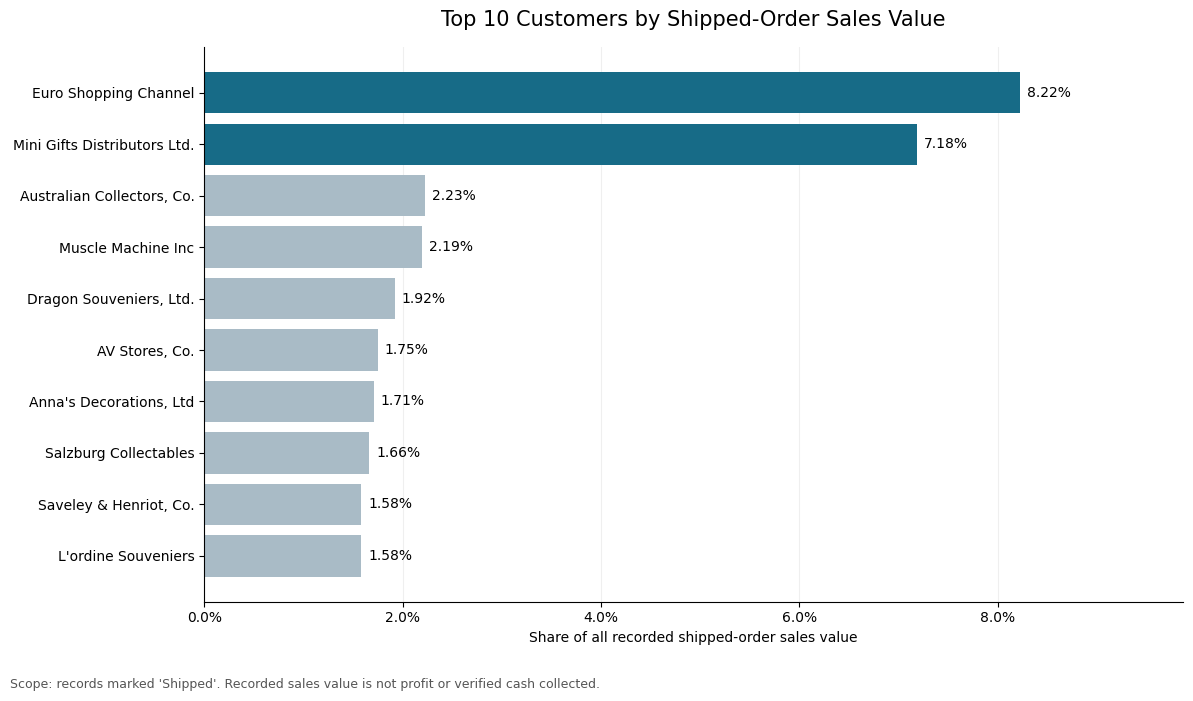

In [25]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from pathlib import Path

top_customers = (
    customer_concentration
    .sort_values("recorded_shipped_sales", ascending=False)
    .head(10)
    .copy()
)

colors = ["#176B87"] * min(2, len(top_customers))
colors += ["#A9BBC6"] * max(0, len(top_customers) - 2)

fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    top_customers["CUSTOMERNAME"],
    top_customers["sales_share_pct"],
    color=colors
)

ax.invert_yaxis()

ax.bar_label(
    bars,
    labels=[
        f"{share:.2f}%"
        for share in top_customers["sales_share_pct"]
    ],
    padding=5
)

ax.set_title(
    "Top 10 Customers by Shipped-Order Sales Value",
    fontsize=15,
    pad=15
)
ax.set_xlabel("Share of all recorded shipped-order sales value")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_xlim(0, top_customers["sales_share_pct"].max() * 1.2)

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.01, 0.01,
    "Scope: records marked 'Shipped'. Recorded sales value is not profit "
    "or verified cash collected.",
    fontsize=9,
    color="#555555"
)

fig.tight_layout(rect=[0, 0.05, 1, 1])

Path("output").mkdir(exist_ok=True)
fig.savefig(
    "output/top_10_customer_concentration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

/tmp/ipykernel_626/516344308.py:6: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  shipped["ORDERDATE"] = pd.to_datetime(


,Order Date,Recorded Shipped Sales
0,2018-01-06,12133.25
1,2018-01-09,11432.34
2,2018-01-10,6864.05
3,2018-01-29,54702.00
4,2018-01-31,44621.96
5,2018-02-11,58871.11
6,2018-02-17,56181.32
7,2018-02-24,25783.76
8,2018-03-03,55245.02
9,2018-03-10,27398.82


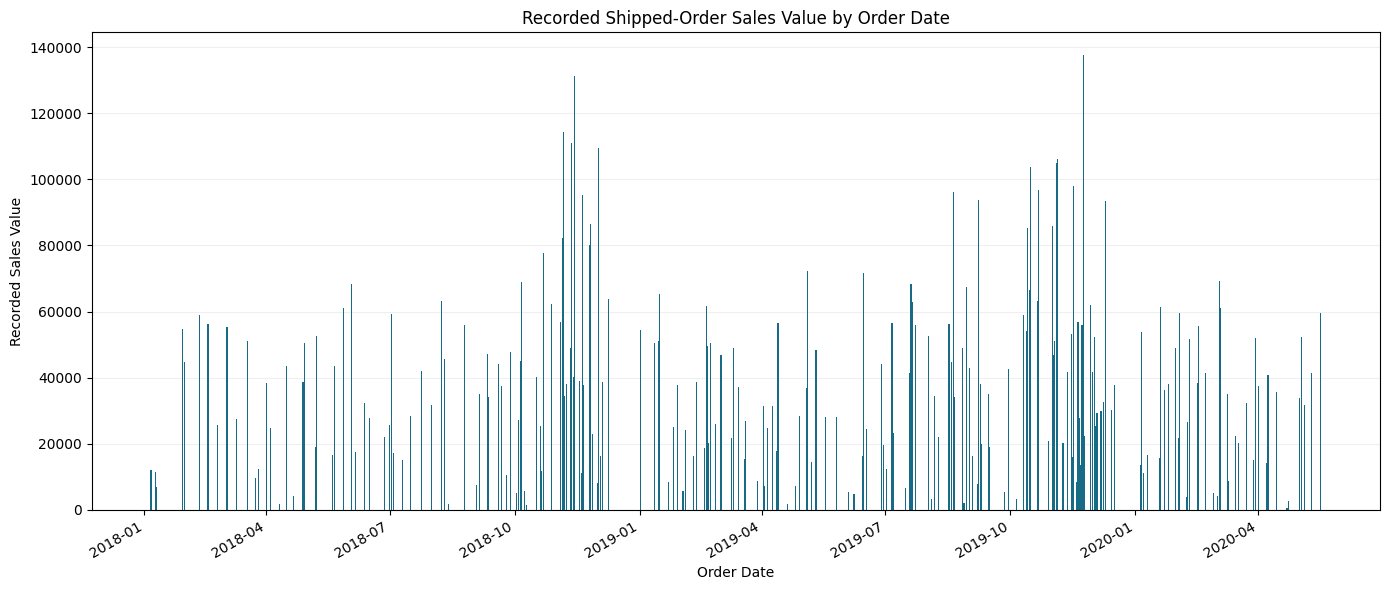

In [26]:


shipped = df.loc[
    df["STATUS"].eq("Shipped"),
    ["ORDERDATE", "SALES"]
].copy()

shipped["ORDERDATE"] = pd.to_datetime(
    shipped["ORDERDATE"], errors="raise"
).dt.normalize()

shipped["SALES"] = pd.to_numeric(
    shipped["SALES"], errors="raise"
)

sales_by_date = (
    shipped.groupby("ORDERDATE", as_index=False)["SALES"]
    .sum()
    .sort_values("ORDERDATE")
    .rename(columns={
        "ORDERDATE": "Order Date",
        "SALES": "Recorded Shipped Sales"
    })
)

display(sales_by_date.head(10))

fig, ax = plt.subplots(figsize=(14, 6))

ax.bar(
    sales_by_date["Order Date"],
    sales_by_date["Recorded Shipped Sales"],
    width=0.8,
    color="#176B87"
)

ax.set_title("Recorded Shipped-Order Sales Value by Order Date")
ax.set_xlabel("Order Date")
ax.set_ylabel("Recorded Sales Value")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.autofmt_xdate()
fig.tight_layout()

Path("output").mkdir(exist_ok=True)

sales_by_date.to_csv(
    "output/sales_by_date.csv",
    index=False,
    date_format="%Y-%m-%d"
)

fig.savefig(
    "output/sales_by_date_bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 2018-2019 holiday period and 2019-2020 holiday period

In [27]:
import pandas as pd
import plotly.express as px
from pathlib import Path

# 1. Filter shipped orders and total sales by country
country_sales = (
    df.loc[df["STATUS"].eq("Shipped"), ["COUNTRY", "SALES"]]
    .copy()
)

country_sales["SALES"] = pd.to_numeric(
    country_sales["SALES"], errors="raise"
)
country_sales["COUNTRY"] = country_sales["COUNTRY"].fillna("Unknown")

country_sales = (
    country_sales.groupby("COUNTRY", as_index=False)["SALES"]
    .sum()
    .sort_values("SALES", ascending=False)
    .rename(columns={
        "COUNTRY": "Country",
        "SALES": "Recorded Shipped Sales"
    })
)

country_sales["Sales Share (%)"] = (
    country_sales["Recorded Shipped Sales"]
    / country_sales["Recorded Shipped Sales"].sum()
    * 100
)

display(country_sales.round(2))

# 2. Draw the interactive map
fig = px.choropleth(
    country_sales,
    locations="Country",
    locationmode="country names",
    color="Recorded Shipped Sales",
    hover_name="Country",
    hover_data={
        "Recorded Shipped Sales": ":,.0f",
        "Sales Share (%)": ":.2f"
    },
    color_continuous_scale="Blues",
    title="Recorded Shipped-Order Sales Value by Country"
)

fig.update_layout(
    geo=dict(
        showframe=False,
        showcoastlines=False,
        projection_type="natural earth"
    ),
    coloraxis_colorbar=dict(
        title="Recorded Sales Value"
    )
)

fig.show()

# 3. Save the data for Google Sheets
Path("output").mkdir(exist_ok=True)

country_sales.to_csv(
    "output/country_sales.csv",
    index=False
)

fig.write_html(
    "output/country_sales_map.html",
    include_plotlyjs="cdn"
)

,Country,Recorded Shipped Sales,Sales Share (%)
18,USA,3099797.14,34.37
6,France,1067131.83,11.83
14,Spain,1044905.31,11.59
0,Australia,572273.58,6.35
17,UK,428472.21,4.75
9,Italy,374674.31,4.15
5,Finland,329581.91,3.65
11,Norway,307463.70,3.41
13,Singapore,288488.41,3.20
3,Canada,224078.56,2.48


,City Label,Recorded_Shipped_Sales,Number_of_Orders,Sales Share (%)
33,"Madrid, Spain",911769.83,27,10.11
59,"San Rafael, USA",647596.31,16,7.18
41,"NYC, USA",515430.11,15,5.71
61,"Singapore, Singapore",288488.41,9,3.20
51,"Paris, France",268944.68,9,2.98
44,"New Bedford, USA",207874.86,6,2.30
37,"Melbourne, Australia",200995.41,5,2.23
7,"Brickhaven, USA",165255.20,8,1.83
42,"Nantes, France",160520.17,6,1.78
35,"Manchester, UK",157807.81,3,1.75


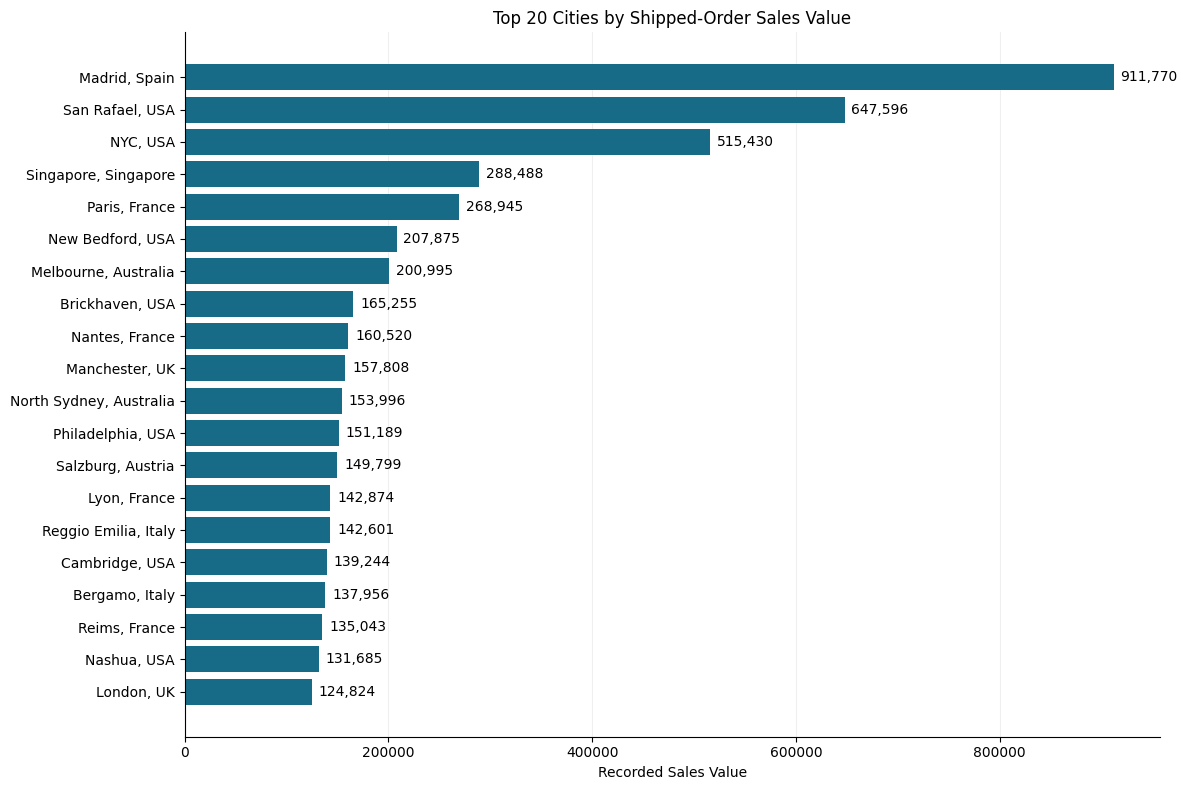

In [28]:
city_sales = df.loc[
    df["STATUS"].eq("Shipped"),
    ["CITY", "COUNTRY", "SALES", "ORDERNUMBER"]
].copy()

city_sales["SALES"] = pd.to_numeric(city_sales["SALES"], errors="raise")
city_sales["CITY"] = city_sales["CITY"].astype(str).str.strip()
city_sales["COUNTRY"] = city_sales["COUNTRY"].astype(str).str.strip()

city_sales = city_sales.replace(
    {"CITY": {"": "Unknown"}, "COUNTRY": {"": "Unknown"}}
)

city_summary = (
    city_sales
    .groupby(["CITY", "COUNTRY"], as_index=False)
    .agg(
        Recorded_Shipped_Sales=("SALES", "sum"),
        Number_of_Orders=("ORDERNUMBER", "nunique")
    )
    .sort_values("Recorded_Shipped_Sales", ascending=False)
)

city_summary["Sales Share (%)"] = (
    city_summary["Recorded_Shipped_Sales"]
    / city_summary["Recorded_Shipped_Sales"].sum()
    * 100
)

top_cities = city_summary.head(20).copy()

top_cities["City Label"] = (
    top_cities["CITY"] + ", " + top_cities["COUNTRY"]
)

display(
    top_cities[
        [
            "City Label",
            "Recorded_Shipped_Sales",
            "Number_of_Orders",
            "Sales Share (%)"
        ]
    ].round(2)
)

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(
    top_cities["City Label"],
    top_cities["Recorded_Shipped_Sales"],
    color="#176B87"
)

ax.invert_yaxis()

ax.bar_label(
    bars,
    labels=[
        f"{value:,.0f}"
        for value in top_cities["Recorded_Shipped_Sales"]
    ],
    padding=5
)

ax.set_title("Top 20 Cities by Shipped-Order Sales Value")
ax.set_xlabel("Recorded Sales Value")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

fig.tight_layout()

Path("output").mkdir(exist_ok=True)

top_cities.to_csv(
    "output/top_20_city_sales.csv",
    index=False
)

fig.savefig(
    "output/top_20_city_sales_bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# According to this most of people are ordering are from spain with 27 orders
# and Sales Share of 10.11%

/tmp/ipykernel_626/2055971425.py:8: UserWarning:

Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.



,Year Quarter,Recorded Shipped Sales,Sales Share (%)
0,2018-Q1,426399.11,4.73
1,2018-Q2,562365.22,6.24
2,2018-Q3,649514.54,7.20
3,2018-Q4,1637473.68,18.16
4,2019-Q1,809841.36,8.98
5,2019-Q2,620484.17,6.88
6,2019-Q3,1109396.27,12.30
7,2019-Q4,1934087.38,21.44
8,2020-Q1,919699.66,10.20
9,2020-Q2,349832.55,3.88


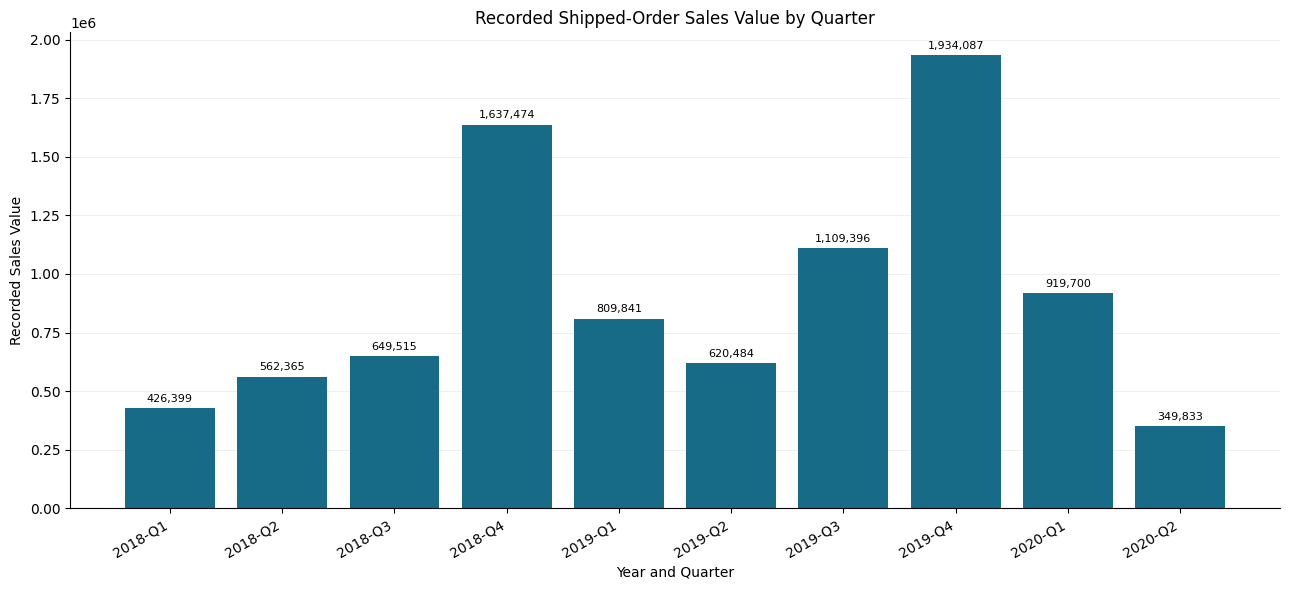

In [29]:

from pathlib import Path

quarter_sales = df.loc[
    df["STATUS"].eq("Shipped"),
    ["ORDERDATE", "SALES"]
].copy()

quarter_sales["ORDERDATE"] = pd.to_datetime(
    quarter_sales["ORDERDATE"], errors="raise"
)

quarter_sales["SALES"] = pd.to_numeric(
    quarter_sales["SALES"], errors="raise"
)

quarter_sales["Year"] = quarter_sales["ORDERDATE"].dt.year
quarter_sales["Quarter"] = quarter_sales["ORDERDATE"].dt.quarter
quarter_sales["Year-Quarter"] = (
    quarter_sales["Year"].astype(str)
    + "-Q"
    + quarter_sales["Quarter"].astype(str)
)

quarter_summary = (
    quarter_sales
    .groupby("Year-Quarter", as_index=False)["SALES"]
    .sum()
    .sort_values("Year-Quarter")
    .rename(columns={
        "Year-Quarter": "Year Quarter",
        "SALES": "Recorded Shipped Sales"
    })
)

total_sales = quarter_summary["Recorded Shipped Sales"].sum()

quarter_summary["Sales Share (%)"] = (
    quarter_summary["Recorded Shipped Sales"] / total_sales * 100
)

display(quarter_summary.round(2))

fig, ax = plt.subplots(figsize=(13, 6))

bars = ax.bar(
    quarter_summary["Year Quarter"],
    quarter_summary["Recorded Shipped Sales"],
    color="#176B87"
)

ax.bar_label(
    bars,
    labels=[
        f"{value:,.0f}"
        for value in quarter_summary["Recorded Shipped Sales"]
    ],
    padding=3,
    fontsize=8
)

ax.set_title("Recorded Shipped-Order Sales Value by Quarter")
ax.set_xlabel("Year and Quarter")
ax.set_ylabel("Recorded Sales Value")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

fig.autofmt_xdate()
fig.tight_layout()

Path("output").mkdir(exist_ok=True)

quarter_summary.to_csv(
    "output/quarter_sales.csv",
    index=False
)

fig.savefig(
    "output/quarter_sales_bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# See Q4 has most sales so at the end of month has the most sales holday Chrismas.

In [30]:
import pandas as pd
import plotly.express as px
from pathlib import Path

# 1. Filter shipped orders
product_sales = df.loc[
    df["STATUS"].eq("Shipped"),
    ["PRODUCTLINE", "SALES"]
].copy()

# 2. Clean the data
product_sales["SALES"] = pd.to_numeric(
    product_sales["SALES"], errors="raise"
)

product_sales["PRODUCTLINE"] = (
    product_sales["PRODUCTLINE"]
    .astype(str)
    .str.strip()
    .replace({"": "Unknown", "nan": "Unknown"})
)

# 3. Total sales by product line
product_summary = (
    product_sales
    .groupby("PRODUCTLINE", as_index=False)["SALES"]
    .sum()
    .sort_values("SALES", ascending=False)
    .rename(columns={
        "PRODUCTLINE": "Product Line",
        "SALES": "Recorded Shipped Sales"
    })
)

product_summary["Sales Share (%)"] = (
    product_summary["Recorded Shipped Sales"]
    / product_summary["Recorded Shipped Sales"].sum()
    * 100
)

display(product_summary.round(2))

# 4. Simple interactive pie chart
fig = px.pie(
    product_summary,
    names="Product Line",
    values="Recorded Shipped Sales",
    title="Share of Shipped-Order Sales Value by Product Line"
)

fig.show()

# 5. Save the results
Path("output").mkdir(exist_ok=True)

product_summary.to_csv(
    "output/product_line_sales.csv",
    index=False
)

fig.write_html(
    "output/product_line_sales_pie.html",
    include_plotlyjs="cdn"
)

# Most of sales are Classic Cars with 40.19%

,Product Line,Recorded Shipped Sales,Sales Share (%)
0,Classic Cars,3625013.21,40.19
6,Vintage Cars,1646602.47,18.26
1,Motorcycles,1066697.68,11.83
5,Trucks and Buses,1027866.74,11.40
2,Planes,860786.42,9.54
3,Ships,576774.85,6.40
4,Trains,215352.57,2.39


In [31]:
# Key finding #
# Customers: Top 10 customers: Euro and Mini Gifts are leading customers,
# including their combined sales share.

# Geography: Country Map: USA is the leading market, including its sales
# share and order count.

# Time: Sales by Quarter: Q4 has the highest sales, describing as a possible
# holiday-season pattern.

# Product: Product-line pie: Classic Cars generated the largest share of record
# shipping order sales value, accounting for 40.19% of total.

# Conclustion #
# Sales were concentrated among a small number of major customers, led by Euro
# and Mini Gifts. France was the strongest geographic market, while classic cars
# was the leading product line. Sales also peaked in Q4, consistant with
# possible holiday demands.

# Recommendation #
# - Maintain strong service and communication with Euro, Mini Gifts and other
# top customers.
# - Review France's performance to understand what drives its strong sales and
# whether similar approaches can support other markets.
# - Ensure Classic Cars inventory and fulfillment can support its high demand
# - Plan invetory, Staffing, and Promition ahead of Q4.
# - Collect promotion, cost, and profit data in the future to evaluate whether
# high-sales products and customers are also profitable.

# Limitation #
# This analysis used recorded sales value from order marked "Skipped". It does
# not include profit, returns, discounts, marketing activity, or verified cash
# collection. Q4 seasonality is an observation, not proof that holiday cause the
# increase.

In [32]:
df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"], errors="raise")

earliest_date = df["ORDERDATE"].min()
latest_date = df["ORDERDATE"].max()

print(f"Earliest order date: {earliest_date:%B %d, %Y}")
print(f"Latest order date: {latest_date:%B %d, %Y}")
print(f"Date range: {earliest_date:%Y-%m-%d} to {latest_date:%Y-%m-%d}")


Earliest order date: January 06, 2018
Latest order date: May 31, 2020
Date range: 2018-01-06 to 2020-05-31


/tmp/ipykernel_626/1604153342.py:1: UserWarning:

Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.

